In [3]:
import numpy as np
import matplotlib.pyplot as plt
from part2 import H_number, H_time
from scipy.sparse import linalg as sla
from myfunctions import rk4solve, lagint

In [4]:
#starting parameters
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
omega= E_c/10 # the amplitude of the drive must be smaller than E_c
H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0] # the energy gap between the ground state and the first excited state
A= U.T @ np.diag(N) @ U #the coupling term between the different states

def f(t,c): #the function for the ODE solver
    return(-1j*H_time(t,H_0,A,omega,w)@c)

In [11]:
c0=np.array([1,0,0]) # the initial condition
t,C = rk4solve(f, c0, 0, 0.005, 40)

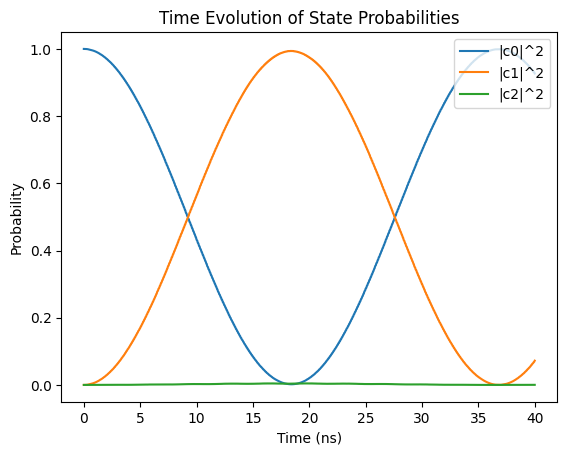

In [12]:
plt.plot(t, np.abs(C[:, 0])**2, label='|c0|^2')
plt.plot(t, np.abs(C[:, 1])**2, label='|c1|^2')
plt.plot(t, np.abs(C[:, 2])**2, label='|c2|^2')
plt.xlabel('Time (ns)')
plt.ylabel('Probability')
plt.title('Time Evolution of State Probabilities')
plt.legend(loc='upper right')
plt.show()


In [13]:
#fing the time of P1 maximum
P1 = np.abs(C[:, 1])**2
i_max = np.argmax(np.abs(C[:, 1])**2)
t_max = t[i_max]
print(t_max)

18.42500000000062


In [14]:
k=4
xp = t[i_max-2*k : i_max+2*k+1 : k]
yp = P1[i_max-2*k : i_max+2*k+1 : k]
x=np.linspace(xp[0], xp[-1], 1000) 
i_max_interp = np.argmax(lagint(x,xp,yp))
t_max_interp = x[i_max_interp]
print(t_max_interp)

18.42383883883946


A pi pulse is achieved at t=18.4238 ns with a maximum population of P1=0.9942


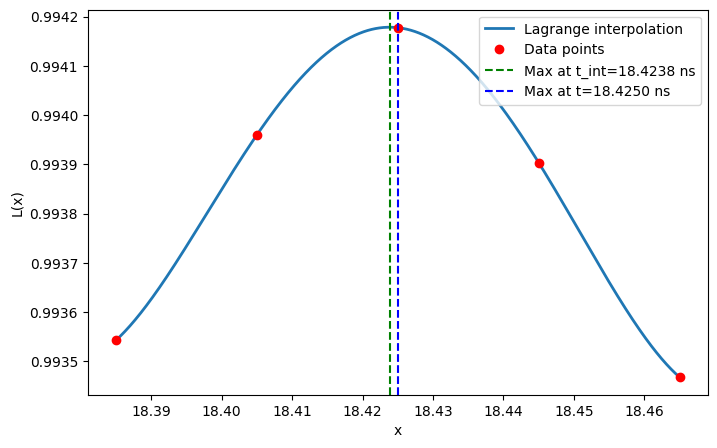

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(x, lagint(x,xp,yp), lw=2, label="Lagrange interpolation")
plt.plot(xp, yp, "ro", label="Data points")
plt.axvline(t_max_interp, color='g', linestyle='--', label=f'Max at t_int={t_max_interp:.4f} ns')   
plt.axvline(t_max, color='b', linestyle='--', label=f'Max at t={t_max:.4f} ns')
plt.xlabel("x"); plt.ylabel("L(x)")
#plt.ylim(0.92, 0.93)
plt.legend(loc='upper right') #right corner
print(f'A pi pulse is achieved at t={t_max_interp:.4f} ns with a maximum population of P1={lagint(t_max_interp,xp,yp):.4f}')
plt.show()
